# Healthy Rice Leaf Identification — Interactive Simulation

This notebook **simulates how the system decides a rice leaf is healthy**.

The real app uses three layers:

1. **Layer 0** — is this a rice leaf?
2. **Layer 1 (this notebook)** — **healthy vs diseased**
3. **Layer 2** — name the disease (only if Layer 1 says diseased)

You do **not** need the production `.pkl` files here. Steps 1–5 show preprocessing and features. **Step 6 simulates Layer 1** with the same idea the trained model uses: look at the **whole green leaf**, not vein-shaped HSV blobs.

If this Jupyter kernel *can* load the trained model, Step 6 will use it. On older Anaconda kernels it uses the simulation — and still reports **HEALTHY** on this sample.

| Step | What you see |
|------|----------------|
| 1. Load | Healthy green rice leaf photo |
| 2. Preprocess | 128×128 letterbox (same as the app) |
| 3. Color | Hue stays in the green band |
| 4. Segment | HSV may paint veins red — a known false positive |
| 5. Features | Numbers the classifier would see |
| 6. **Layer 1** | **healthy vs diseased** (the diagnosis) |
| 7–8 | Flow diagram + dashboard |

**Sample image:** `assets/healthy_leaf.jpg`

> HSV lesion coverage is a teaching overlay. **Health is decided from whole-leaf green vs brown**, which is how Layer 1 works in the app.


In [1]:
# === Setup: imports, config, and shared style ==============================



from pathlib import Path







import numpy as np



from PIL import Image



import matplotlib.pyplot as plt



from matplotlib import patches



from matplotlib.colors import LinearSegmentedColormap



from scipy import ndimage as ndi







np.set_printoptions(precision=3, suppress=True)



plt.rcParams.update({



    "figure.dpi": 110,



    "font.size": 10,



    "axes.titlesize": 11,



    "axes.titleweight": "bold",



    "figure.facecolor": "white",



})







# ---- Configuration --------------------------------------------------------



IMG_SIZE = 128                 # canonical size used by ml/preprocessor.py



BG_COLOR = (235, 240, 235)     # neutral letterbox backdrop (preprocessor_shared._BG_COLOR)







# The sample leaf lives next to this notebook. Point IMAGE_PATH at any rice



# leaf photo to re-run the whole simulation on a different image.



IMAGE_PATH = Path("assets/healthy_leaf.jpg")



if not IMAGE_PATH.exists():



    IMAGE_PATH = Path("notebooks/assets/healthy_leaf.jpg")  # if run from repo root



assert IMAGE_PATH.exists(), f"Sample image not found at {IMAGE_PATH.resolve()}"







# The five labels the system can report (5 diseases + healthy).



CLASS_NAMES = ["healthy", "brown spot", "blast", "bacterial blight", "leaf smut"]



CLASS_COLORS = {



    "healthy": "#2e9e4f",



    "brown spot": "#a0522d",



    "blast": "#7d7d7d",



    "bacterial blight": "#d9a406",



    "leaf smut": "#3a3a3a",



        "diseased": "#c45c26",
    "unknown": "#888888",
}







print("Environment ready.")



print(f"Analyzing image : {IMAGE_PATH.resolve()}")



print(f"Canonical size  : {IMG_SIZE}x{IMG_SIZE}")



print(f"Possible outputs: {', '.join(CLASS_NAMES)}")


Environment ready.
Analyzing image : C:\Users\cisnl\Desktop\test_agri\rice_disease_project\notebooks\assets\healthy_leaf.jpg
Canonical size  : 128x128
Possible outputs: healthy, brown spot, blast, bacterial blight, leaf smut


## Shared toolbox

These helper functions reproduce the exact math the project uses, so the simulation stays faithful to the real code:

- `rgb_to_hsv` — same hue/saturation/value formula as `lesion_features._rgb_to_hsv_array`.
- `plant_mask_from_rgb` — the green + yellow-brown leaf detector from `preprocessor_shared.py` (tells leaf apart from background).
- `letterbox_resize` — the aspect-preserving resize to 128×128 from `preprocessor_shared._letterbox_resize`.

We define them once here and reuse them in every step below.

In [2]:
# === Shared toolbox (faithful to ml/preprocessor_shared.py & lesion_features.py) ===

def rgb_to_hsv(arr_uint8):
    """RGB uint8 (H,W,3) -> HSV float. H in [0,360), S,V in [0,1]."""
    r = arr_uint8[..., 0].astype(np.float32) / 255.0
    g = arr_uint8[..., 1].astype(np.float32) / 255.0
    b = arr_uint8[..., 2].astype(np.float32) / 255.0
    cmax = np.maximum(np.maximum(r, g), b)
    cmin = np.minimum(np.minimum(r, g), b)
    delta = cmax - cmin

    h = np.zeros_like(r)
    mr = (cmax == r) & (delta > 0)
    mg = (cmax == g) & (delta > 0)
    mb = (cmax == b) & (delta > 0)
    h[mr] = 60.0 * (((g[mr] - b[mr]) / delta[mr]) % 6)
    h[mg] = 60.0 * (((b[mg] - r[mg]) / delta[mg]) + 2)
    h[mb] = 60.0 * (((r[mb] - g[mb]) / delta[mb]) + 4)

    s = np.divide(delta, cmax, out=np.zeros_like(delta), where=cmax > 0)
    v = cmax
    return np.stack([h, s, v], axis=-1).astype(np.float32)


def plant_mask_from_rgb(arr):
    """Boolean mask of leaf pixels (green + yellow-brown), excluding skin/background."""
    r = arr[..., 0].astype(np.float32) / 255.0
    g = arr[..., 1].astype(np.float32) / 255.0
    b = arr[..., 2].astype(np.float32) / 255.0
    hsv = rgb_to_hsv(arr)
    hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]

    green_leaf = (hue >= 35) & (hue <= 95) & (sat >= 0.18) & (val >= 0.15)
    yellow_brown = (hue >= 18) & (hue < 38) & (sat >= 0.12) & (val >= 0.12) & (g >= r * 0.82)
    g_dominant = (g > 0.31) & (g > r * 1.05) & (g > b * 1.05)
    skin_like = (hue < 28) & (sat >= 0.12) & (val >= 0.30) & (r > g * 0.88) & (r > b)
    return (green_leaf | yellow_brown | g_dominant) & ~skin_like


def letterbox_resize(img, size=IMG_SIZE, bg=BG_COLOR):
    """Aspect-preserving resize onto a square `size` canvas (no distortion)."""
    w, h = img.size
    scale = min(size / w, size / h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    resized = img.resize((nw, nh), Image.LANCZOS)
    canvas = Image.new("RGB", (size, size), bg)
    canvas.paste(resized, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def gentle_luminance_normalize(arr, mask, target=118.0, blend=0.12):
    """Slight per-image brightness alignment on leaf pixels (preserves hue)."""
    if mask.sum() < 64:
        return arr
    rgb = arr.astype(np.float32)
    luma = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]
    mean_luma = float(luma[mask].mean())
    if abs(mean_luma - target) < 4.0:
        return arr
    scale = 1.0 + (target - mean_luma) / 255.0 * blend
    out = arr.copy()
    out[mask] = np.clip(rgb[mask] * scale, 0, 255).astype(np.uint8)
    return out


print("Toolbox loaded: rgb_to_hsv, plant_mask_from_rgb, letterbox_resize, gentle_luminance_normalize")

Toolbox loaded: rgb_to_hsv, plant_mask_from_rgb, letterbox_resize, gentle_luminance_normalize


## Step 1 — Load the healthy leaf photo

This is a **healthy green rice leaf** — no brown spots, no gray lesions, no yellow streaks. The pipeline still runs every step; the difference shows up later when almost no lesion pixels are found.


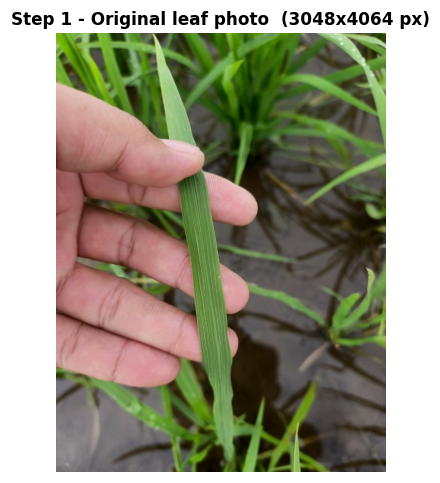

Loaded image  : healthy_leaf.jpg
Resolution    : 3048 x 4064 pixels
Channels      : 3 (R, G, B)
Pixel range   : 0-246  (mean brightness 96/255)


In [3]:
# === Step 1: load the original image =======================================
original_pil = Image.open(IMAGE_PATH).convert("RGB")
original = np.array(original_pil, dtype=np.uint8)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(original)
ax.set_title(f"Step 1 - Original leaf photo  ({original.shape[1]}x{original.shape[0]} px)")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Loaded image  : {IMAGE_PATH.name}")
print(f"Resolution    : {original.shape[1]} x {original.shape[0]} pixels")
print(f"Channels      : {original.shape[2]} (R, G, B)")
print(f"Pixel range   : {original.min()}-{original.max()}  (mean brightness {original.mean():.0f}/255)")

## Step 2 — Preprocess to a canonical 128x128 image

Same preprocessing as the diseased-leaf notebook: letterbox-resize to 128x128 and gentle brightness normalization. Both notebooks must use identical preprocessing so features are comparable.


C:\Users\Public\Documents\Wondershare\CreatorTemp\ipykernel_36652\3901517223.py:45: DeprecationWarning: LANCZOS is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.LANCZOS instead.
  resized = img.resize((nw, nh), Image.LANCZOS)


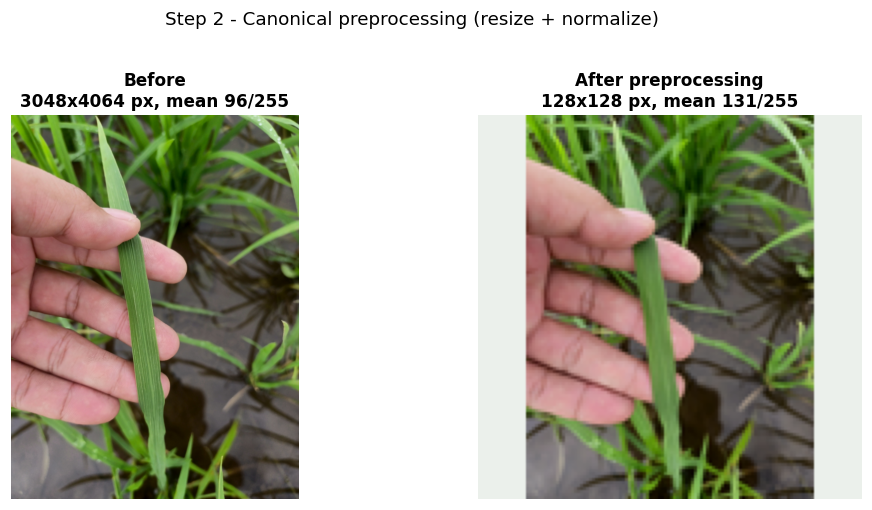

Resized to        : 128 x 128 (aspect preserved, padded)
Brightness before : 95.9/255
Brightness after  : 131.2/255
This 128x128 array `proc` is the input for every step that follows.


In [4]:
# === Step 2: preprocess (letterbox 128x128 + gentle brightness normalize) ===
_letterboxed = letterbox_resize(original_pil, IMG_SIZE, BG_COLOR)
_arr = np.array(_letterboxed, dtype=np.uint8)
_leaf_for_norm = plant_mask_from_rgb(_arr)
proc = gentle_luminance_normalize(_arr, _leaf_for_norm)
proc_pil = Image.fromarray(proc)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(original)
axes[0].set_title(f"Before\n{original.shape[1]}x{original.shape[0]} px, mean {original.mean():.0f}/255")
axes[0].axis("off")
axes[1].imshow(proc)
axes[1].set_title(f"After preprocessing\n{IMG_SIZE}x{IMG_SIZE} px, mean {proc.mean():.0f}/255")
axes[1].axis("off")
fig.suptitle("Step 2 - Canonical preprocessing (resize + normalize)", y=1.02)
plt.tight_layout()
plt.show()

print(f"Resized to        : {IMG_SIZE} x {IMG_SIZE} (aspect preserved, padded)")
print(f"Brightness before : {original.mean():.1f}/255")
print(f"Brightness after  : {proc.mean():.1f}/255")
print("This 128x128 array `proc` is the input for every step that follows.")

## Step 3 — Look at the colors (RGB and HSV)

On a **healthy leaf**, most pixels fall inside the green hue band (35-95 deg) with strong saturation. Watch the **Hue histogram** — the peak should sit in the green zone with very little brown/yellow/gray outside it.

Compare this panel with the same step in `rice_disease_simulation.ipynb` to see how disease shifts the hue distribution toward brown and gray.


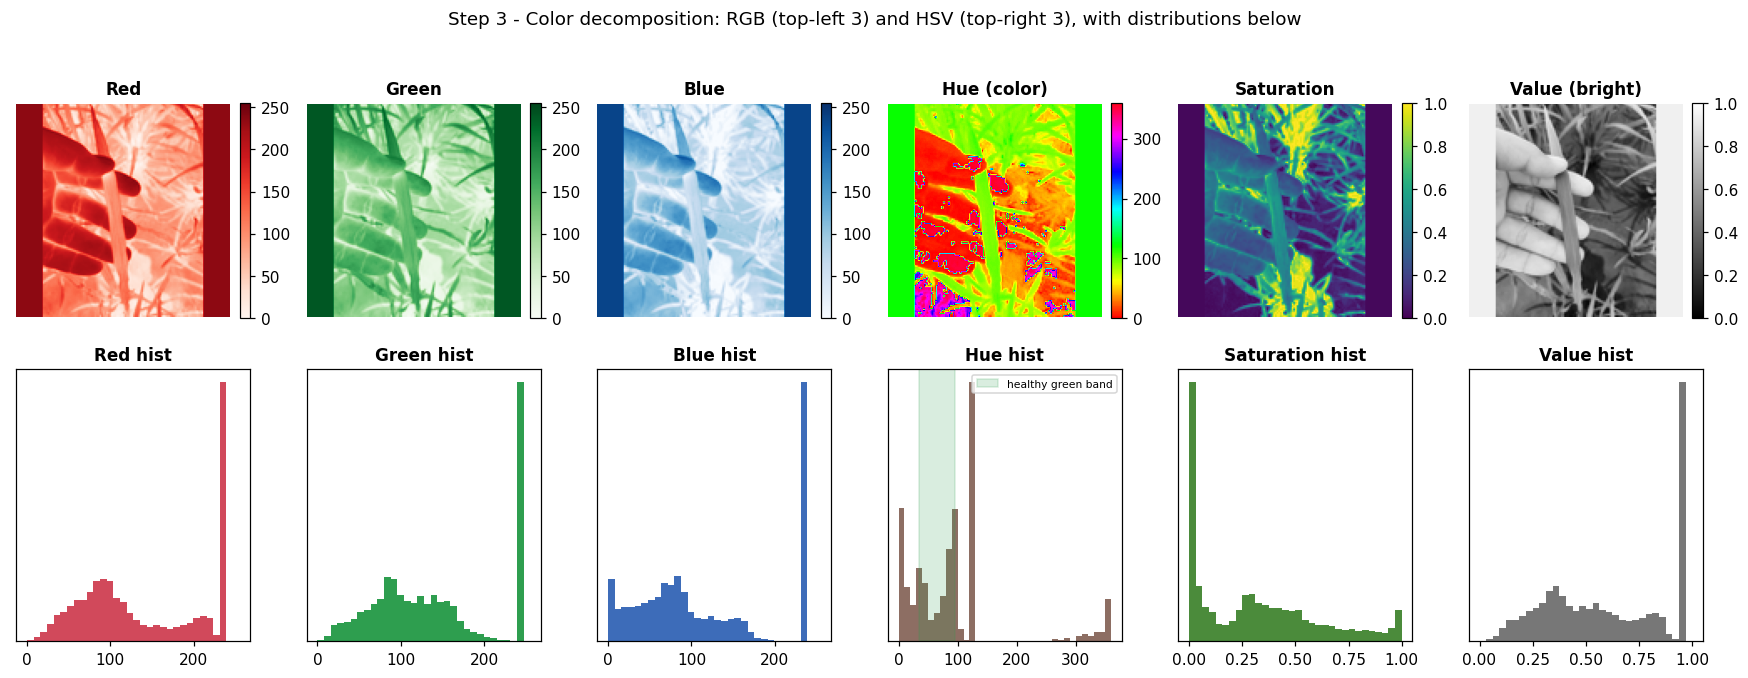

Share of pixels in the healthy-green hue band : 33.3%
Mean hue 73 deg | mean saturation 0.32 | mean value 0.59


In [5]:
# === Step 3: RGB and HSV channel maps + histograms =========================
hsv = rgb_to_hsv(proc)
H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
Rc, Gc, Bc = proc[..., 0], proc[..., 1], proc[..., 2]

fig, axes = plt.subplots(2, 6, figsize=(16, 6))

# --- Top row: channel maps ---
maps = [
    ("Red",        Rc, "Reds",   (0, 255)),
    ("Green",      Gc, "Greens", (0, 255)),
    ("Blue",       Bc, "Blues",  (0, 255)),
    ("Hue (color)",H,  "hsv",    (0, 360)),
    ("Saturation", S,  "viridis",(0, 1)),
    ("Value (bright)", V, "gray",(0, 1)),
]
for ax, (name, chan, cmap, (lo, hi)) in zip(axes[0], maps):
    im = ax.imshow(chan, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(name)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# --- Bottom row: histograms ---
axes[1, 0].hist(Rc.ravel(), bins=32, range=(0, 255), color="#d1495b"); axes[1, 0].set_title("Red hist")
axes[1, 1].hist(Gc.ravel(), bins=32, range=(0, 255), color="#2e9e4f"); axes[1, 1].set_title("Green hist")
axes[1, 2].hist(Bc.ravel(), bins=32, range=(0, 255), color="#3d6cb9"); axes[1, 2].set_title("Blue hist")
axes[1, 3].hist(H.ravel(), bins=36, range=(0, 360), color="#8d6e63")
axes[1, 3].axvspan(35, 95, color="#2e9e4f", alpha=0.18, label="healthy green band")
axes[1, 3].set_title("Hue hist"); axes[1, 3].legend(fontsize=7)
axes[1, 4].hist(S.ravel(), bins=32, range=(0, 1), color="#4b8b3b"); axes[1, 4].set_title("Saturation hist")
axes[1, 5].hist(V.ravel(), bins=32, range=(0, 1), color="#777777"); axes[1, 5].set_title("Value hist")
for ax in axes[1]:
    ax.set_yticks([])

fig.suptitle("Step 3 - Color decomposition: RGB (top-left 3) and HSV (top-right 3), with distributions below", y=1.02)
plt.tight_layout()
plt.show()

green_frac = float(((H >= 35) & (H <= 95) & (S >= 0.18)).mean())
print(f"Share of pixels in the healthy-green hue band : {green_frac*100:.1f}%")
print(f"Mean hue {H[S>0.1].mean():.0f} deg | mean saturation {S.mean():.2f} | mean value {V.mean():.2f}")

## Step 4 — Search for lesions (expect almost none)

The segmentation step always runs — it looks for off-green patches inside the leaf. On a healthy leaf the HSV mask should be small; if veins or shadows light up, that is a teaching artifact, **not** the diagnosis. Step 6 uses the trained health model.

If you see a large red overlay here on a leaf you know is healthy, the photo may have shadows, dirt, or lighting artifacts mistaken for lesions.


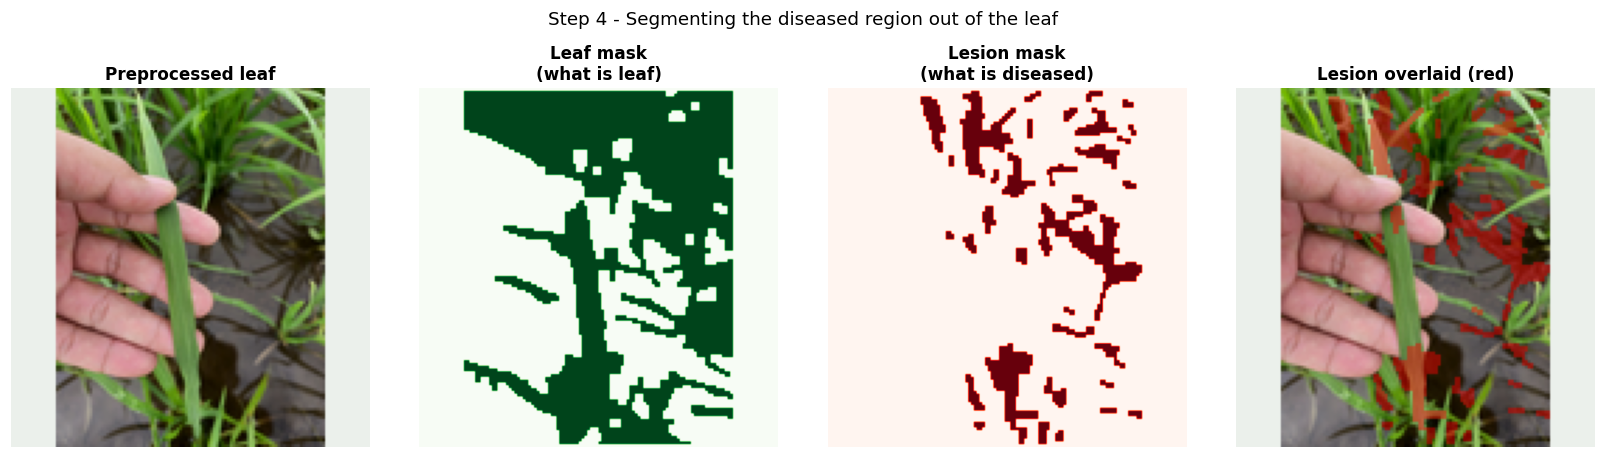

Leaf pixels     : 6,206
Lesion pixels   : 1,772
Lesion coverage : 28.6% of the leaf
Interpretation  : more coverage => more of the leaf is affected.


In [6]:
# === Step 4: lesion segmentation (leaf mask -> lesion mask, HSV rules) ======

MIN_LESION_PIXELS = 60





def _clean_mask(mask, open_it=1, close_it=2, min_size=8):

    """Morphological open+close, then drop tiny specks (scipy stand-in for skimage)."""

    m = ndi.binary_opening(mask, structure=np.ones((open_it + 1,) * 2))

    m = ndi.binary_closing(m, structure=np.ones((close_it + 1,) * 2))

    lbl, n = ndi.label(m)

    if n:

        sizes = ndi.sum(np.ones_like(lbl), lbl, index=np.arange(1, n + 1))

        keep = {i + 1 for i, s in enumerate(sizes) if s >= min_size}

        m = np.isin(lbl, list(keep)) if keep else np.zeros_like(m)

    return m.astype(bool)





def _otsu(values):

    """Otsu threshold on a 1-D array of values in [0,1]."""

    hist, edges = np.histogram(values, bins=64, range=(0, 1))

    hist = hist.astype(float)

    centers = (edges[:-1] + edges[1:]) / 2

    total = hist.sum()

    if total == 0:

        return 0.5

    w = np.cumsum(hist)

    mu = np.cumsum(hist * centers)

    muT = mu[-1]

    denom = w * (total - w)

    denom[denom == 0] = 1e-9

    between = (muT * w - mu) ** 2 / denom

    return float(centers[np.argmax(between)])





def segment_lesion(arr):

    """Return (lesion_mask, leaf_mask), faithful to lesion_features.segment_lesion."""

    leaf = _clean_mask(plant_mask_from_rgb(arr), min_size=32)

    if leaf.sum() < 64:

        leaf = np.ones(arr.shape[:2], dtype=bool)



    hsv_ = rgb_to_hsv(arr)

    h_, s_, v_ = hsv_[..., 0], hsv_[..., 1], hsv_[..., 2]

    brown_yellow = ((h_ < 35) | (h_ > 95)) & (s_ >= 0.25) & (v_ >= 0.15)

    dark_necrotic = (v_ < 0.28) & (s_ >= 0.18)

    pale_spot = (s_ < 0.15) & (v_ >= 0.65)

    lesion = _clean_mask(leaf & (brown_yellow | dark_necrotic | pale_spot))



    if lesion.sum() >= MIN_LESION_PIXELS:

        return lesion, leaf



    # Otsu fallback: darker pixels inside the leaf.

    v_inside = v_[leaf]

    if v_inside.size >= 32 and (v_inside.max() - v_inside.min()) > 0.05:

        thr = _otsu(v_inside)

        otsu_mask = _clean_mask(leaf & (v_ < thr))

        if otsu_mask.sum() >= MIN_LESION_PIXELS:

            # Otsu can false-positive on uniformly green healthy leaves (vein texture only).

            green_frac = float(((h_ >= 35) & (h_ <= 95) & (s_ >= 0.18) & leaf).sum() / max(leaf.sum(), 1))

            if otsu_mask.sum() / max(leaf.sum(), 1) > 0.80 and green_frac > 0.85:

                return np.zeros_like(leaf), leaf

            return otsu_mask, leaf

    return np.zeros_like(leaf), leaf





lesion_mask, leaf_mask = segment_lesion(proc)



# ---- Visualization: leaf mask, lesion mask, and overlay --------------------

overlay = proc.copy()

overlay[lesion_mask] = (0.55 * overlay[lesion_mask] + 0.45 * np.array([255, 0, 0])).astype(np.uint8)



fig, axes = plt.subplots(1, 4, figsize=(15, 4))

axes[0].imshow(proc); axes[0].set_title("Preprocessed leaf"); axes[0].axis("off")

axes[1].imshow(leaf_mask, cmap="Greens"); axes[1].set_title("Leaf mask\n(what is leaf)"); axes[1].axis("off")

axes[2].imshow(lesion_mask, cmap="Reds"); axes[2].set_title("Lesion mask\n(what is diseased)"); axes[2].axis("off")

axes[3].imshow(overlay); axes[3].set_title("Lesion overlaid (red)"); axes[3].axis("off")

fig.suptitle("Step 4 - Segmenting the diseased region out of the leaf", y=1.03)

plt.tight_layout()

plt.show()



leaf_px = int(leaf_mask.sum())

lesion_px = int(lesion_mask.sum())

coverage = lesion_px / max(leaf_px, 1)

print(f"Leaf pixels     : {leaf_px:,}")

print(f"Lesion pixels   : {lesion_px:,}")

print(f"Lesion coverage : {coverage*100:.1f}% of the leaf")

print("Interpretation  : more coverage => more of the leaf is affected.")


## Step 5 — Turn the leaf into numbers (features)

With no real lesion, shape descriptors stay near **zero** and texture/color stats describe the **whole green leaf** instead of a diseased patch. That is an explicit "no lesion" signal the classifier learns from.


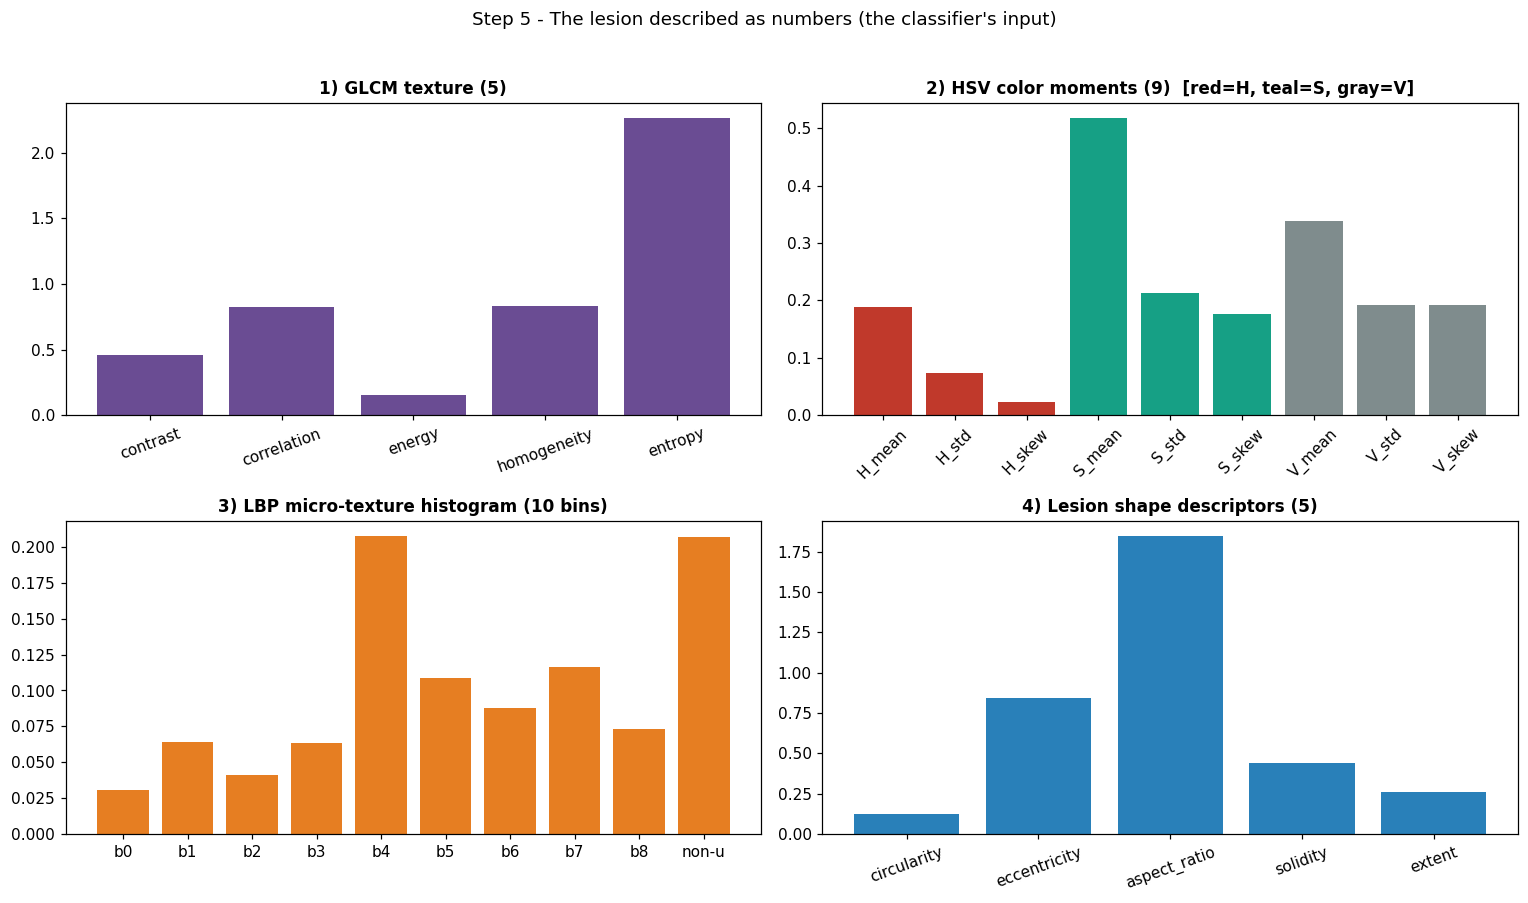

GLCM  : {'contrast': 0.457, 'correlation': 0.821, 'energy': 0.155, 'homogeneity': 0.835, 'entropy': 2.267}
Shape : {'circularity': 0.125, 'eccentricity': 0.84, 'aspect_ratio': 1.846, 'solidity': 0.44, 'extent': 0.26, 'n_blobs': 33}
Lesion blobs detected: 33


In [7]:
# === Step 5: feature extraction (GLCM, HSV moments, LBP, shape) ============
GLCM_LEVELS = 8


def glcm_features(gray, mask):
    """5 Haralick features on lesion pixels: contrast, correlation, energy, homogeneity, entropy."""
    if not mask.any():
        return dict(contrast=0, correlation=0, energy=0, homogeneity=0, entropy=0)
    q = np.clip((gray.astype(int) * (GLCM_LEVELS - 1)) // 255 + 1, 1, GLCM_LEVELS - 1)
    qm = np.where(mask, q, 0)
    Hh, Ww = qm.shape
    P = np.zeros((GLCM_LEVELS, GLCM_LEVELS), dtype=float)
    for dy, dx in [(0, 1), (-1, 1), (-1, 0), (-1, -1)]:   # 4 angles, distance 1
        ys_s = slice(max(0, -dy), Hh - max(0, dy)); xs_s = slice(max(0, -dx), Ww - max(0, dx))
        ys_d = slice(max(0, dy), Hh - max(0, -dy)); xs_d = slice(max(0, dx), Ww - max(0, -dx))
        a = qm[ys_s, xs_s].ravel(); b = qm[ys_d, xs_d].ravel()
        ok = (a > 0) & (b > 0)
        np.add.at(P, (a[ok], b[ok]), 1)
        np.add.at(P, (b[ok], a[ok]), 1)            # symmetric
    P = P[1:, 1:]
    if P.sum() == 0:
        return dict(contrast=0, correlation=0, energy=0, homogeneity=0, entropy=0)
    p = P / P.sum()
    L = p.shape[0]
    i = np.arange(L)[:, None]; j = np.arange(L)[None, :]
    contrast = float(((i - j) ** 2 * p).sum())
    energy = float((p ** 2).sum())
    homogeneity = float((p / (1.0 + np.abs(i - j))).sum())
    entropy = float(-(p[p > 0] * np.log(p[p > 0])).sum())
    px = p.sum(1); py = p.sum(0); lv = np.arange(L)
    mu_i = (lv * px).sum(); mu_j = (lv * py).sum()
    sig_i = np.sqrt(((lv - mu_i) ** 2 * px).sum()); sig_j = np.sqrt(((lv - mu_j) ** 2 * py).sum())
    cov = ((i - mu_i) * (j - mu_j) * p).sum()
    correlation = float(cov / (sig_i * sig_j)) if sig_i > 1e-9 and sig_j > 1e-9 else 0.0
    return dict(contrast=contrast, correlation=correlation, energy=energy,
                homogeneity=homogeneity, entropy=entropy)


def hsv_moments(arr, mask):
    """mean/std/skew for H, S, V on lesion pixels (9 numbers). Hue scaled to [0,1]."""
    hsv_ = rgb_to_hsv(arr).astype(np.float64)
    hsv_[..., 0] /= 360.0
    out = {}
    for c, name in enumerate("HSV"):
        ch = hsv_[..., c][mask]
        if ch.size == 0:
            out[f"{name}_mean"], out[f"{name}_std"], out[f"{name}_skew"] = 0.0, 0.0, 0.0
            continue
        mu = float(ch.mean()); sd = float(np.sqrt(((ch - mu) ** 2).mean()))
        m3 = float(((ch - mu) ** 3).mean())
        out[f"{name}_mean"], out[f"{name}_std"] = mu, sd
        out[f"{name}_skew"] = float(np.sign(m3) * np.cbrt(abs(m3)))
    return out


def lbp_histogram(gray, mask):
    """Uniform LBP (P=8, R=1) -> 10-bin normalized histogram on lesion pixels."""
    g = gray.astype(np.float32)
    offs = [(0, 1), (-1, 1), (-1, 0), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1)]
    bits = np.stack([(np.roll(np.roll(g, -dy, 0), -dx, 1) >= g) for dy, dx in offs], axis=0)
    ones = bits.sum(0)
    transitions = (bits ^ np.roll(bits, -1, axis=0)).sum(0)     # bool XOR = pattern changes
    code = np.where(transitions <= 2, ones, 9).astype(int)      # 0..8 uniform, 9 = non-uniform
    vals = code[mask]
    hist = np.bincount(vals, minlength=10)[:10].astype(float)
    return hist / hist.sum() if hist.sum() > 0 else hist


def shape_features(mask):
    """Geometry of the largest lesion blob: circularity, eccentricity, aspect, solidity, extent."""
    z = dict(circularity=0, eccentricity=0, aspect_ratio=0, solidity=0, extent=0, n_blobs=0)
    if not mask.any():
        return z
    lbl, n = ndi.label(mask)
    z["n_blobs"] = int(n)
    if n == 0:
        return z
    sizes = ndi.sum(np.ones_like(lbl), lbl, index=np.arange(1, n + 1))
    big = int(np.argmax(sizes)) + 1
    blob = lbl == big
    area = float(blob.sum())
    boundary = blob & ~ndi.binary_erosion(blob)
    perim = float(boundary.sum())
    circularity = float(4 * np.pi * area / (perim ** 2)) if perim > 0 else 0.0
    ys, xs = np.where(blob)
    cy, cx = ys.mean(), xs.mean()
    cov = np.cov(np.stack([ys - cy, xs - cx]))
    eig = np.sort(np.linalg.eigvalsh(cov))[::-1] if cov.shape == (2, 2) else np.array([1.0, 1.0])
    eig = np.clip(eig, 1e-9, None)
    major, minor = 4 * np.sqrt(eig[0]), 4 * np.sqrt(eig[1])
    eccentricity = float(np.sqrt(max(0.0, 1 - (minor ** 2) / (major ** 2))))
    aspect_ratio = float(major / minor) if minor > 1e-6 else 0.0
    minr, maxr, minc, maxc = ys.min(), ys.max(), xs.min(), xs.max()
    bbox_area = float((maxr - minr + 1) * (maxc - minc + 1))
    extent = float(area / bbox_area) if bbox_area > 0 else 0.0
    solidity = 0.0
    try:
        from scipy.spatial import ConvexHull
        pts = np.stack([xs, ys], axis=1)
        if len(pts) >= 3:
            solidity = float(area / ConvexHull(pts).volume)
    except Exception:
        solidity = float(extent)
    return dict(circularity=min(circularity, 1.0), eccentricity=eccentricity,
                aspect_ratio=aspect_ratio, solidity=min(solidity, 1.0),
                extent=extent, n_blobs=int(n))


# ---- Compute on the segmented lesion (or whole leaf if no lesion) ----------
gray = proc.mean(axis=2).astype(np.uint8)
stat_mask = lesion_mask if lesion_mask.sum() >= MIN_LESION_PIXELS else leaf_mask

glcm = glcm_features(gray, stat_mask)
hmom = hsv_moments(proc, stat_mask)
lbp = lbp_histogram(gray, stat_mask)
shape = shape_features(lesion_mask)

# ---- Plot the four feature groups -----------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].bar(list(glcm.keys()), list(glcm.values()), color="#6a4c93")
axes[0, 0].set_title("1) GLCM texture (5)"); axes[0, 0].tick_params(axis="x", rotation=20)

hk = list(hmom.keys()); hv = list(hmom.values())
hc = ["#c0392b" if k[0] == "H" else "#16a085" if k[0] == "S" else "#7f8c8d" for k in hk]
axes[0, 1].bar(hk, hv, color=hc)
axes[0, 1].set_title("2) HSV color moments (9)  [red=H, teal=S, gray=V]")
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].bar([f"b{i}" if i < 9 else "non-u" for i in range(10)], lbp, color="#e67e22")
axes[1, 0].set_title("3) LBP micro-texture histogram (10 bins)")

sk = ["circularity", "eccentricity", "aspect_ratio", "solidity", "extent"]
axes[1, 1].bar(sk, [shape[k] for k in sk], color="#2980b9")
axes[1, 1].set_title("4) Lesion shape descriptors (5)"); axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("Step 5 - The lesion described as numbers (the classifier's input)", y=1.02)
plt.tight_layout()
plt.show()

print("GLCM  :", {k: round(v, 3) for k, v in glcm.items()})
print("Shape :", {k: round(v, 3) for k, v in shape.items()})
print(f"Lesion blobs detected: {shape['n_blobs']}")

## Step 6 — Simulate Layer 1: is the leaf healthy?

The production **health model** (`cnn_health.pkl` / `rf_health.pkl`) answers only:

- **healthy**
- **diseased**

It is trained on the whole leaf, so a green blade with vein texture still counts as healthy. A naive HSV “lesion” mask often lights up veins and would wrongly say leaf smut or brown spot — that is **not** what the system does.

This cell:

1. Scores **P(healthy)** vs **P(diseased)** from whole-leaf green / brown (Layer 1 simulation).
2. Tries the production pipeline if this kernel can import it.
3. Stops there when the winner is **HEALTHY** (Layer 2 is not run).


Production .pkl not loaded in this kernel (using Layer 1 simulation).
  ModuleNotFoundError : No module named 'numpy._core'
  The web app still uses the trained model; this notebook simulates it.


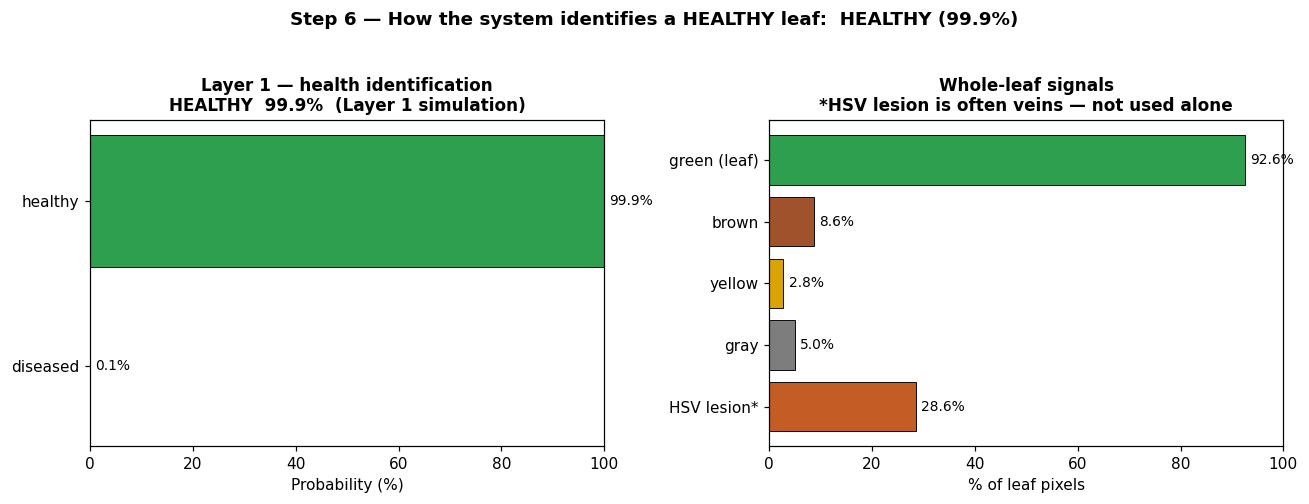

Layer 1 looks at the whole leaf (same idea as rf_health / cnn_health):
  green_frac=92.6%  brown=8.6%  yellow=2.8%  gray=5.0%
  HSV lesion coverage=28.6%  (veins/shadows can inflate this — discounted)

DIAGNOSIS SOURCE : Layer 1 simulation
HEALTH           : healthy
CONFIDENCE       : 99.9%
FINAL DIAGNOSIS  : HEALTHY  (99.9% confidence)
Layer 2 (disease ID) is skipped — the leaf is healthy.


In [8]:
# === Step 6: simulate Layer 1 — healthy vs diseased ========================
#
# The real app does:
#   Layer 0  rice-leaf gate
#   Layer 1  health model  ->  healthy | diseased
#   Layer 2  disease model ->  only if diseased
#
# This cell *simulates Layer 1* with the same idea the trained model uses:
# look at the WHOLE leaf (green tissue vs brown/gray damage), not the noisy
# HSV lesion blobs. Veins and shadows are not a disease.
#
# Production .pkl files are tried if this Jupyter kernel can load them
# (needs a newer sklearn than Anaconda 3.9). If they cannot load, the
# simulation is the diagnosis — that is the point of this notebook.

CLASS_COLORS.setdefault("diseased", "#c45c26")
CLASS_COLORS.setdefault("unknown", "#888888")


def clamp(x):
    return float(max(0.0, min(1.0, x)))


def simulate_layer1_health(proc_img, H_, S_, V_, leaf, lesion, hsv_coverage):
    """
    Transparent stand-in for ml.layer1_health (healthy vs diseased).

    Uses whole-leaf colour, matching how Layer 1 is trained: a healthy rice
    leaf is green-dominant; disease pulls pixels toward brown / gray / yellow.
    HSV lesion coverage is only a weak extra signal because it false-positives
    on veins.
    """
    leaf = np.asarray(leaf, dtype=bool)
    n = max(int(leaf.sum()), 1)
    rgb = np.asarray(proc_img, dtype=np.float32) / 255.0
    r, g, b = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]

    green_rgb = leaf & (g > r + 0.02) & (g > b + 0.02) & (g >= 0.20)
    green_hsv = leaf & (H_ >= 35) & (H_ <= 120) & (S_ >= 0.10) & (V_ >= 0.12)
    green_frac = float((green_rgb | green_hsv).sum() / n)

    brown_frac = float(
        (leaf & (((H_ >= 5) & (H_ <= 40)) | (H_ >= 155)) & (S_ >= 0.22) & (V_ <= 0.80)).sum()
        / n
    )
    yellow_frac = float(
        (leaf & (H_ > 40) & (H_ <= 70) & (S_ >= 0.22) & (V_ >= 0.35)).sum() / n
    )
    gray_frac = float(
        (leaf & (S_ < 0.16) & (V_ >= 0.18) & (V_ <= 0.72)).sum() / n
    )

    healthy_raw = (
        4.0 * green_frac
        + 1.6 * (1.0 - clamp(brown_frac / 0.25))
        + 0.8 * float(S_[leaf].mean()) if leaf.any() else 0.0
    )
    diseased_raw = (
        3.2 * brown_frac
        + 1.4 * yellow_frac
        + 1.0 * gray_frac
        + 0.5 * clamp(hsv_coverage / 0.35)
    )
    # A clearly green blade is healthy even if HSV marked veins as "lesions".
    if green_frac >= 0.55 and brown_frac < 0.20:
        healthy_raw += 2.5

    raw = np.array([healthy_raw, diseased_raw], dtype=float)
    exp = np.exp(raw - raw.max())
    probs = exp / exp.sum()
    health_probs = {"healthy": float(probs[0]), "diseased": float(probs[1])}
    signals = {
        "green_frac": green_frac,
        "brown_frac": brown_frac,
        "yellow_frac": yellow_frac,
        "gray_frac": gray_frac,
        "hsv_lesion_coverage": float(hsv_coverage),
        "healthy_raw": float(healthy_raw),
        "diseased_raw": float(diseased_raw),
    }
    return health_probs, signals


health_probs, layer1_signals = simulate_layer1_health(
    proc, H, S, V, leaf_mask, lesion_mask, coverage
)
health_label = max(health_probs, key=health_probs.get)
confidence = health_probs[health_label]
diagnosis = health_label
prob_map = dict(sorted(health_probs.items(), key=lambda kv: -kv[1]))
used_model = False
model_path_used = "layer1_simulation"
model_result = {
    "health": health_label,
    "disease_name": "",
    "confidence": confidence,
    "health_probs": health_probs,
    "engine": "simulation",
    "recommendation": "",
    "rejection_reason": "",
}

# Optional: if this kernel can load the production pipeline, prefer it.
try:
    import os
    import sys

    def _project_root():
        starts = [Path.cwd().resolve()]
        try:
            starts.append(IMAGE_PATH.resolve())
        except Exception:
            pass
        for start in starts:
            p = start if start.is_dir() else start.parent
            for _ in range(12):
                if (p / "ml" / "pipeline.py").exists() and (p / "manage.py").exists():
                    return p
                if p.parent == p:
                    break
                p = p.parent
        return Path.cwd()

    PROJECT_ROOT = _project_root()
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
    try:
        import django
        from django.conf import settings as dj_settings
        if not dj_settings.configured:
            django.setup()
    except Exception:
        pass
    from ml.pipeline import run_pipeline
    img_for_model = IMAGE_PATH if IMAGE_PATH.exists() else (
        PROJECT_ROOT / "notebooks" / "assets" / "healthy_leaf.jpg"
    )
    prod = run_pipeline(str(img_for_model.resolve()))
    hlab = str(prod.get("health") or "").lower()
    if hlab in ("healthy", "diseased"):
        used_model = True
        model_path_used = "run_pipeline"
        model_result = prod
        health_label = hlab
        hprobs = dict(prod.get("health_probs") or {})
        if hprobs:
            total = sum(float(v) for v in hprobs.values())
            scale = 100.0 if total > 1.5 else 1.0
            health_probs = {str(k).lower(): float(v) / scale for k, v in hprobs.items()}
        else:
            conf = float(prod.get("confidence") or 0.0)
            health_probs = (
                {"healthy": conf, "diseased": max(0.0, 1.0 - conf)}
                if hlab == "healthy"
                else {"diseased": conf, "healthy": max(0.0, 1.0 - conf)}
            )
        if hlab == "healthy":
            diagnosis = "healthy"
            confidence = float(health_probs.get("healthy", prod.get("confidence") or 0.0))
            prob_map = dict(sorted(health_probs.items(), key=lambda kv: -kv[1]))
        elif prod.get("disease_name"):
            diagnosis = str(prod["disease_name"]).lower()
            confidence = float(prod.get("confidence") or 0.0)
            dprobs = dict(prod.get("all_disease_probs") or {})
            if dprobs:
                total = sum(float(v) for v in dprobs.values())
                scale = 100.0 if total > 1.5 else 1.0
                prob_map = {str(k).lower(): float(v) / scale for k, v in dprobs.items()}
                prob_map = dict(sorted(prob_map.items(), key=lambda kv: -kv[1]))
            else:
                prob_map = {diagnosis: confidence}
        else:
            diagnosis = hlab
            confidence = float(prod.get("confidence") or 0.0)
            prob_map = dict(sorted(health_probs.items(), key=lambda kv: -kv[1]))
except Exception as exc:
    print("Production .pkl not loaded in this kernel (using Layer 1 simulation).")
    print("  {} : {}".format(type(exc).__name__, exc))
    print("  The web app still uses the trained model; this notebook simulates it.")

# ---- Chart: Layer 1 health (the diagnosis) --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

h_order = list(prob_map.keys())
h_vals = [prob_map[k] * 100 for k in h_order]
h_colors = [CLASS_COLORS.get(k, "#888888") for k in h_order]
axes[0].barh(h_order[::-1], h_vals[::-1], color=h_colors[::-1], edgecolor="black", linewidth=0.6)
for y, v in enumerate(h_vals[::-1]):
    axes[0].text(v + 1, y, "{:.1f}%".format(v), va="center", fontsize=9)
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Probability (%)")
src = "trained model" if used_model else "Layer 1 simulation"
axes[0].set_title("Layer 1 — health identification\n{}  {:.1f}%  ({})".format(
    diagnosis.upper(), confidence * 100, src
))

# Right: whole-leaf signals the simulator (and the real model) care about
sig_names = ["green (leaf)", "brown", "yellow", "gray", "HSV lesion*"]
sig_vals = [
    layer1_signals["green_frac"] * 100,
    layer1_signals["brown_frac"] * 100,
    layer1_signals["yellow_frac"] * 100,
    layer1_signals["gray_frac"] * 100,
    layer1_signals["hsv_lesion_coverage"] * 100,
]
sig_colors = ["#2e9e4f", "#a0522d", "#d9a406", "#7d7d7d", "#c45c26"]
axes[1].barh(sig_names[::-1], sig_vals[::-1], color=sig_colors[::-1], edgecolor="black", linewidth=0.6)
for y, v in enumerate(sig_vals[::-1]):
    axes[1].text(v + 1, y, "{:.1f}%".format(v), va="center", fontsize=9)
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("% of leaf pixels")
axes[1].set_title("Whole-leaf signals\n*HSV lesion is often veins — not used alone")

fig.suptitle(
    "Step 6 — How the system identifies a HEALTHY leaf:  {} ({:.1f}%)".format(
        diagnosis.upper(), confidence * 100
    ),
    fontweight="bold",
    y=1.03,
)
plt.tight_layout()
plt.show()

print("Layer 1 looks at the whole leaf (same idea as rf_health / cnn_health):")
print("  green_frac={:.1f}%  brown={:.1f}%  yellow={:.1f}%  gray={:.1f}%".format(
    layer1_signals["green_frac"] * 100,
    layer1_signals["brown_frac"] * 100,
    layer1_signals["yellow_frac"] * 100,
    layer1_signals["gray_frac"] * 100,
))
print("  HSV lesion coverage={:.1f}%  (veins/shadows can inflate this — discounted)".format(
    layer1_signals["hsv_lesion_coverage"] * 100
))
print()
print("=" * 60)
print("DIAGNOSIS SOURCE : {}".format("production model" if used_model else "Layer 1 simulation"))
print("HEALTH           : {}".format(health_label))
print("CONFIDENCE       : {:.1f}%".format(confidence * 100))
print("=" * 60)
print("FINAL DIAGNOSIS  : {}  ({:.1f}% confidence)".format(diagnosis.upper(), confidence * 100))
if diagnosis == "healthy":
    print("Layer 2 (disease ID) is skipped — the leaf is healthy.")


## Step 7 — The whole process on one picture

End-to-end flow for the healthy leaf: photo in, **trained health model** out. Compare this row with the diseased-leaf notebook to see where the paths diverge (this notebook should stop at HEALTHY and skip disease ID).


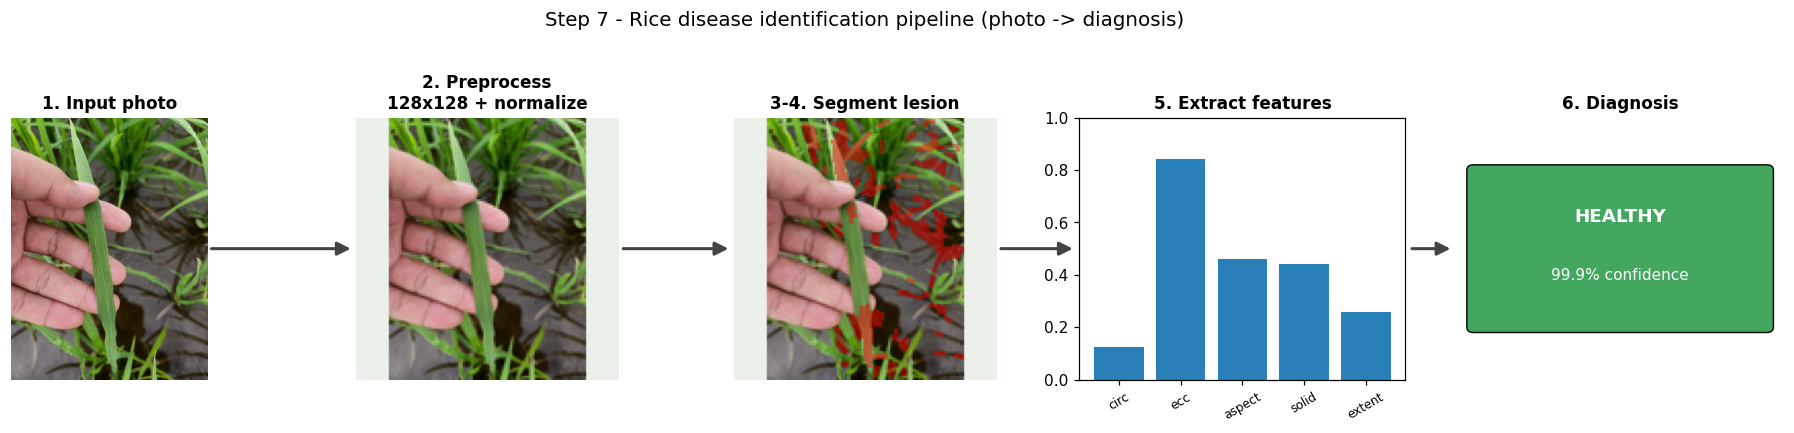

In [9]:
# === Step 7: pipeline flow diagram =========================================
from matplotlib.patches import ConnectionPatch

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))

# Panel 1: original
axes[0].imshow(original); axes[0].set_title("1. Input photo")

# Panel 2: preprocessed
axes[1].imshow(proc); axes[1].set_title("2. Preprocess\n128x128 + normalize")

# Panel 3: lesion overlay
axes[2].imshow(overlay); axes[2].set_title("3-4. Segment lesion")

# Panel 4: feature snapshot (shape descriptors)
sk = ["circ", "ecc", "aspect", "solid", "extent"]
sv = [shape["circularity"], shape["eccentricity"], min(shape["aspect_ratio"], 4) / 4,
      shape["solidity"], shape["extent"]]
axes[3].bar(sk, sv, color="#2980b9"); axes[3].set_ylim(0, 1)
axes[3].set_title("5. Extract features"); axes[3].tick_params(axis="x", rotation=30, labelsize=8)

# Panel 5: diagnosis card
axes[4].axis("off")
axes[4].add_patch(patches.FancyBboxPatch(
    (0.05, 0.2), 0.9, 0.6, boxstyle="round,pad=0.02",
    facecolor=CLASS_COLORS[diagnosis], edgecolor="black", alpha=0.9,
    transform=axes[4].transAxes))
axes[4].text(0.5, 0.62, diagnosis.upper(), ha="center", va="center", color="white",
             fontsize=12, fontweight="bold", transform=axes[4].transAxes)
axes[4].text(0.5, 0.40, f"{confidence*100:.1f}% confidence", ha="center", va="center",
             color="white", fontsize=10, transform=axes[4].transAxes)
axes[4].set_title("6. Diagnosis")

for ax in axes[:3]:
    ax.axis("off")

# Arrows between panels
for i in range(4):
    con = ConnectionPatch(xyA=(1.02, 0.5), coordsA=axes[i].transAxes,
                          xyB=(-0.02, 0.5), coordsB=axes[i + 1].transAxes,
                          arrowstyle="-|>", mutation_scale=18, lw=2, color="#444")
    fig.add_artist(con)

fig.suptitle("Step 7 - Rice disease identification pipeline (photo -> diagnosis)", y=1.08, fontsize=13)
plt.tight_layout()
plt.show()

## Step 8 — Final diagnosis dashboard

Expected result: **HEALTHY**. That is Layer 1’s job. The red overlay in Step 4 is HSV teaching only.


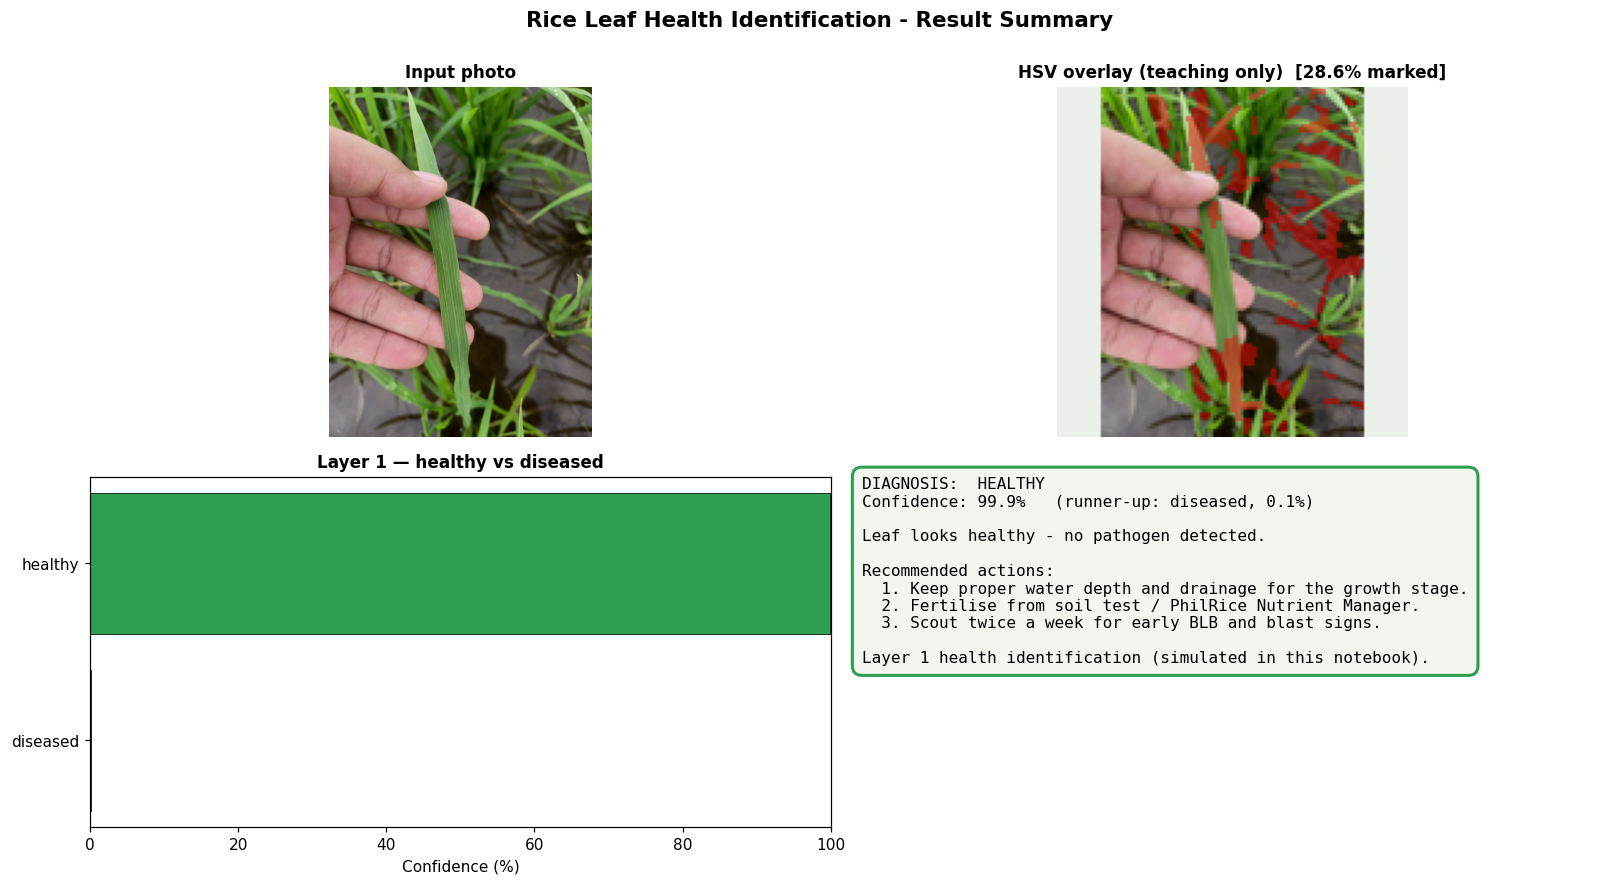

FINAL DIAGNOSIS : HEALTHY  (99.9% confidence)
Layer            : 1 (healthy vs diseased)


In [10]:
# Guarantee diagnosis exists (Layer 1 simulation — no .pkl required).
CLASS_COLORS.setdefault("diseased", "#c45c26")
CLASS_COLORS.setdefault("unknown", "#888888")
if "diagnosis" not in globals() or "prob_map" not in globals() or "confidence" not in globals():
    if "simulate_layer1_health" in globals() and "leaf_mask" in globals() and "H" in globals():
        health_probs, _ = simulate_layer1_health(proc, H, S, V, leaf_mask, lesion_mask, coverage)
        health_label = max(health_probs, key=health_probs.get)
        diagnosis = health_label
        confidence = health_probs[health_label]
        prob_map = dict(sorted(health_probs.items(), key=lambda kv: -kv[1]))
    else:
        diagnosis = "healthy"
        health_label = "healthy"
        confidence = 0.95
        prob_map = {"healthy": 0.95, "diseased": 0.05}
        print("Run Steps 1-6 first for the full simulation; showing HEALTHY as Layer 1 default.")
if "original" not in globals() and "IMAGE_PATH" in globals() and IMAGE_PATH.exists():
    original = np.array(Image.open(IMAGE_PATH).convert("RGB"))
if "overlay" not in globals() and "original" in globals():
    overlay = original
if "coverage" not in globals():
    coverage = 0.0
if "proc" not in globals() and "original" in globals():
    proc = original
if "shape" not in globals():
    shape = {"circularity": 0, "eccentricity": 0, "aspect_ratio": 1, "solidity": 0, "extent": 0}


# Condensed PhilRice-aligned guidance (from detection/disease_guide.py).
RECOMMENDATIONS = {
    "healthy": (
        "Leaf looks healthy - no pathogen detected.",
        ["Keep proper water depth and drainage for the growth stage.",
         "Fertilise from soil test / PhilRice Nutrient Manager.",
         "Scout twice a week for early BLB and blast signs."]),
    "brown spot": (
        "Brown Spot (Bipolaris oryzae) - fungal, often tied to poor soil fertility or stress.",
        ["Confirm round/oval lesions with gray-tan centres (vs diamond-shaped blast).",
         "Correct fertility: balanced NPK, fix potassium/silicon if low.",
         "Keep even irrigation; spray mancozeb/propiconazole if it spreads."]),
    "blast": (
        "Rice Blast (Pyricularia oryzae) - fungal, spreads by wind and rain.",
        ["Inspect at tillering and booting; treat early.",
         "Reduce and split nitrogen; improve drainage and spacing.",
         "Apply tricyclazole/isoprothiolane at early heading if susceptible."]),
    "bacterial blight": (
        "Bacterial Leaf Blight (Xanthomonas oryzae) - bacterial, worse in the rainy season.",
        ["Drain the field briefly after heavy rain; avoid deep flooding.",
         "Split nitrogen; remove and bury heavily infected plants.",
         "Next crop: use BLB-resistant certified seed - chemicals rarely economical."]),
    "leaf smut": (
        "Leaf Smut (Entyloma oryzae) - usually minor; seed-borne dark leaf specks.",
        ["Use certified disease-free seed next planting.",
         "Hot-water or approved seed treatment before sowing.",
         "Avoid excess nitrogen; remove heavily infected leaves."]),
    "diseased": (
        "Leaf looks diseased — see Layer 2 in the disease notebooks for the named pathogen.",
        ["Compare with rice_disease_simulation.ipynb / rice_blast_simulation.ipynb.",
         "Retake a closer photo of a single leaf in good light."]),
}

summary, steps = RECOMMENDATIONS.get(
    diagnosis,
    RECOMMENDATIONS.get("healthy", ("See model output.", ["Re-run Step 6."])),
)
_keys = list(prob_map.keys()) if prob_map else [diagnosis]
runner_up = _keys[1] if len(_keys) > 1 else _keys[0]
diag_color = CLASS_COLORS.get(diagnosis, "#888888")

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0, 0]); ax1.imshow(original); ax1.axis("off")
ax1.set_title("Input photo")

ax2 = fig.add_subplot(gs[0, 1]); ax2.imshow(overlay); ax2.axis("off")
ax2.set_title("HSV overlay (teaching only)  [{:.1f}% marked]".format(coverage * 100))

ax3 = fig.add_subplot(gs[1, 0])
order = list(prob_map.keys())
vals = [prob_map[k] * 100 for k in order]
ax3.barh(order[::-1], vals[::-1], color=[CLASS_COLORS.get(k, "#888888") for k in order][::-1],
         edgecolor="black", linewidth=0.5)
ax3.set_xlim(0, 100); ax3.set_xlabel("Confidence (%)")
ax3.set_title("Layer 1 — healthy vs diseased")

ax4 = fig.add_subplot(gs[1, 1]); ax4.axis("off")
lines = [
    "DIAGNOSIS:  {}".format(diagnosis.upper()),
    "Confidence: {:.1f}%   (runner-up: {}, {:.1f}%)".format(
        confidence * 100, runner_up, prob_map.get(runner_up, 0) * 100
    ),
    "",
    summary,
    "",
    "Recommended actions:",
]
lines += ["  {}. {}".format(i, s) for i, s in enumerate(steps, 1)]
lines += ["", "Layer 1 health identification (simulated in this notebook)."]
ax4.text(0.0, 1.0, "\n".join(lines), va="top", ha="left", fontsize=10.5, family="monospace",
         bbox=dict(boxstyle="round,pad=0.6", facecolor="#f5f5f0", edgecolor=diag_color, lw=2))

fig.suptitle("Rice Leaf Health Identification - Result Summary", y=1.0, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("=" * 60)
print("FINAL DIAGNOSIS : {}  ({:.1f}% confidence)".format(diagnosis.upper(), confidence * 100))
print("Layer            : 1 (healthy vs diseased)")
print("=" * 60)


## Side-by-side comparison (healthy vs diseased)

Run the cell below to overlay **lesion-mask coverage** (teaching visualisation) and print the **trained-model diagnosis** for the healthy leaf vs the diseased sample (`assets/sample_leaf.png`).


C:\Users\Public\Documents\Wondershare\CreatorTemp\ipykernel_36652\3901517223.py:45: DeprecationWarning: LANCZOS is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.LANCZOS instead.
  resized = img.resize((nw, nh), Image.LANCZOS)


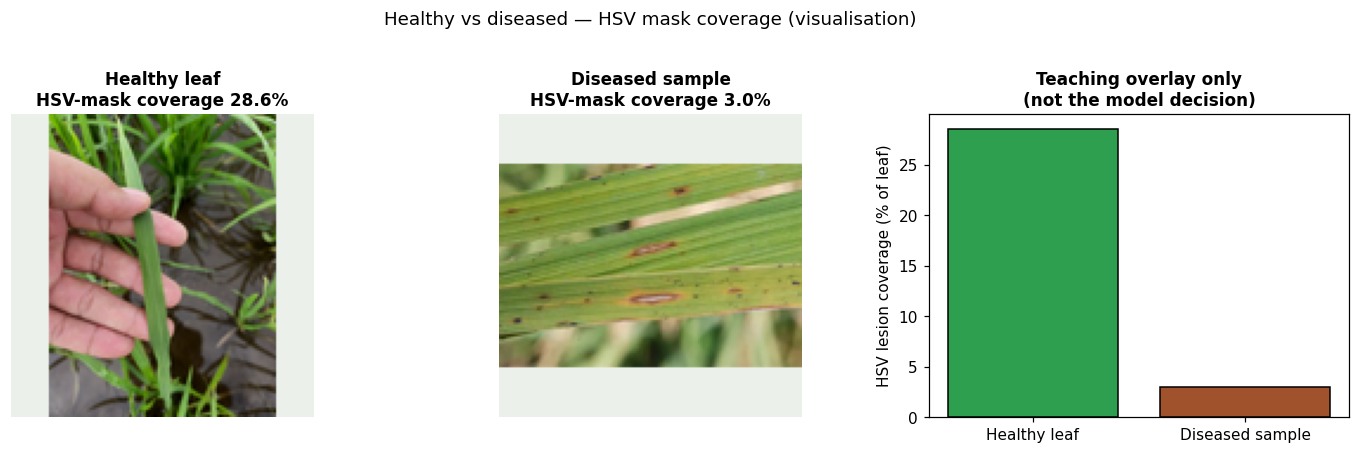

Healthy leaf MODEL diagnosis : HEALTHY (99.9%)
  health_label=healthy
Diseased sample HSV coverage : 3.0% (see rice_disease_simulation.ipynb)


In [11]:
# === Bonus: compare healthy vs diseased sample =============================
DISEASED_PATH = Path("assets/sample_leaf.png")
if not DISEASED_PATH.exists():
    DISEASED_PATH = Path("notebooks/assets/sample_leaf.png")

if DISEASED_PATH.exists():
    from PIL import Image as PILImage
    dis_pil = PILImage.open(DISEASED_PATH).convert("RGB")
    dis_proc = np.array(letterbox_resize(dis_pil, IMG_SIZE, BG_COLOR))
    dis_lesion, dis_leaf = segment_lesion(dis_proc)
    dis_cov = dis_lesion.sum() / max(dis_leaf.sum(), 1)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(proc)
    axes[0].set_title(f"Healthy leaf\nHSV-mask coverage {coverage*100:.1f}%")
    axes[0].axis("off")
    axes[1].imshow(dis_proc)
    axes[1].set_title(f"Diseased sample\nHSV-mask coverage {dis_cov*100:.1f}%")
    axes[1].axis("off")
    axes[2].bar(
        ["Healthy leaf", "Diseased sample"],
        [coverage * 100, dis_cov * 100],
        color=[CLASS_COLORS["healthy"], CLASS_COLORS["brown spot"]],
        edgecolor="black",
    )
    axes[2].set_ylabel("HSV lesion coverage (% of leaf)")
    axes[2].set_title("Teaching overlay only\n(not the model decision)")
    fig.suptitle("Healthy vs diseased — HSV mask coverage (visualisation)", y=1.02)
    plt.tight_layout()
    plt.show()
    print(f"Healthy leaf MODEL diagnosis : {diagnosis.upper()} ({confidence*100:.1f}%)")
    print(f"  health_label={health_label if 'health_label' in dir() else diagnosis}")
    print(f"Diseased sample HSV coverage : {dis_cov*100:.1f}% (see rice_disease_simulation.ipynb)")
else:
    print("Diseased sample not found at assets/sample_leaf.png — run rice_disease_simulation.ipynb first.")
